# EDA - Exploratory Data Analysis
> Note: This EDA is performed on stratified samples (1000 rows) of the original datasets
> for faster exploration. Key findings will be validated on the full datasets in later stages.

## Load the datasets

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_context("notebook")

In [2]:
creditcard = pd.read_csv("../data/sample/creditcard_sample.csv")
paysim = pd.read_csv("../data/sample/paysim_sample.csv")

In [4]:
creditcard.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,32612.0,0.920370,0.059459,0.338209,2.625480,-0.369010,-0.596594,0.324602,-0.115699,-0.593968,...,0.079354,-0.195536,-0.166161,0.356617,0.464388,0.025773,-0.054372,0.041309,148.33,0
1,82239.0,1.313726,-1.168423,-0.099724,-1.461302,-1.126195,-0.696335,-0.508839,-0.219071,-2.412583,...,-0.468437,-1.287024,0.060182,-0.052531,0.219926,-0.537523,-0.013343,0.024838,120.19,0
2,46212.0,1.478065,-1.030126,0.966802,-1.244331,-1.959864,-0.980621,-1.217493,-0.186538,-1.685564,...,-0.034669,0.337716,0.035759,0.728506,0.312604,-0.125327,0.055413,0.031448,11.20,0
3,46736.0,-2.697005,-3.456521,1.368304,1.163658,3.153533,-3.014808,-2.227578,0.234370,-1.703262,...,0.071523,-0.464281,0.881652,0.463650,-0.694408,-0.577752,0.098236,0.279537,23.66,0
4,67721.0,1.237322,0.243815,0.172440,0.505730,-0.215366,-0.574754,-0.073264,0.006048,-0.094286,...,-0.266507,-0.838154,0.084792,-0.062395,0.206152,0.100144,-0.031983,0.015613,1.29,0


In [5]:
paysim.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,204,CASH_OUT,357077.61,C1647007305,9094.0,0.0,C1041978037,1793158.54,2150236.15,0,0
1,347,CASH_OUT,131728.94,C897220994,0.0,0.0,C1316117987,485417.31,617146.25,0,0
2,205,CASH_OUT,370229.29,C960594717,104825.0,0.0,C1543635842,2203623.01,2573852.29,0,0
3,279,CASH_OUT,260326.66,C1147619833,0.0,0.0,C1588910554,463200.38,723527.04,0,0
4,351,PAYMENT,7331.70,C518521481,0.0,0.0,M1713003902,0.00,0.00,0,0


In [6]:
creditcard.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     1000 non-null   float64
 22  V

The creditcard sample contains 1000 rows and 31 columns. All features are stored as floating-point values. `Class` column which is the target, is integer.  

In the `Class` column, 1 indicates fraudulent transactions and 0 indicates normal ones. This dataset is suitable for both supervised fraud classification and unsupervised anomaly detection due to its extreme class imbalance. 

As mentioned in the official dataset description in Kaggle, most features (`V1` - `V28`) are PCA-transformed and anonymized due to confidentiality concerns, meaning their original semantic meaning is unknown. This limits interpretability but simplifies preprocessing and reduces the need for extensive scaling compared to raw transactional data.

In [7]:
paysim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            1000 non-null   int64  
 1   type            1000 non-null   object 
 2   amount          1000 non-null   float64
 3   nameOrig        1000 non-null   object 
 4   oldbalanceOrg   1000 non-null   float64
 5   newbalanceOrig  1000 non-null   float64
 6   nameDest        1000 non-null   object 
 7   oldbalanceDest  1000 non-null   float64
 8   newbalanceDest  1000 non-null   float64
 9   isFraud         1000 non-null   int64  
 10  isFlaggedFraud  1000 non-null   int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 86.1+ KB


The paysim sample contains 1000 rows and 11 columns. Most features are floating points. There's also categorical columns including `type`, `nameOrig`, and `nameDest` columns. There are also three integer columns: `step`, `isFraud`, and `isFlaggedFraud`.

The primary target variable is `isFraud`. The `isFlaggedFraud` column represents rule-based detection and should not be used as a predictive feature to avoid leakage.

Columns related to account balances (`oldbalance*`, `newbalance*`) should be used with caution. In some fraud cases, transactions are canceled, which can lead to inconsistent or misleading balance values. These features may introduce partial leakage or distort model learning if not handled carefully.

### Implications for preprocessing
- Numerical features require scaling due to different ranges, especially in the PaySim dataset.
- Categorical features in PaySim require encoding.
- Columns that introduce leakage must be excluded.
- Severe class imbalance must be handled carefully during evaluation. 

## Class Imbalance Analysis

### creditcard dataset

In [ ]:
# class frequency in target variable
class_count = creditcard['Class'].value_counts()

Class
0    998
1      2
Name: count, dtype: int64

In [62]:
# percentage of each class in target variable
creditcard['Class'].value_counts(normalize=True) * 100

Class
0    99.8
1     0.2
Name: proportion, dtype: float64

In [63]:
# create dataframe for plotting
class_count_df = class_count.reset_index()
# rename columns
class_count_df.columns = ['Class', 'Count']
class_count_df

,Class,Count
0,0,998
1,1,2


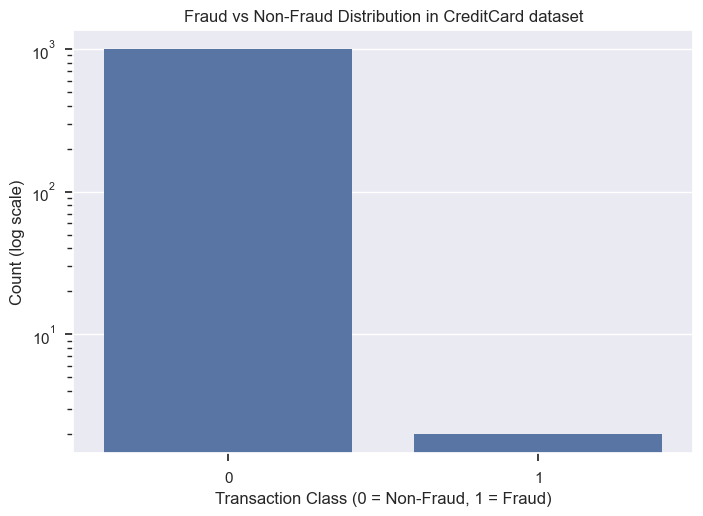

In [64]:
# plotting class distribution
sns.barplot(
    x='Class',
    y='Count', 
    data=class_count_df
)

plt.yscale('log')
plt.title('Fraud vs Non-Fraud Distribution in CreditCard dataset')
plt.xlabel("Transaction Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Count (log scale)")

plt.show()

#### Interpretation 
We can clearly observe the imbalance in the dataset. Only **0.2** percent of transactions are fraudulent. So it is necessary to be cautious about the metrics we use to evaluate our model. For instance, high accuracy could be obviously very misleading as the model can falsely learn to just predict non-fraud for each transaction and get a high accuracy. 

This highlights the need for alternative evaluation metrics such as precision, recall, and F1-score in later stages.

### paysim dataset

In [65]:
# class frequency in target variable
class_count = paysim['isFraud'].value_counts()
class_count

isFraud
0    999
1      1
Name: count, dtype: int64

In [66]:
# percentage of each class in target variable
paysim['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.9
1     0.1
Name: proportion, dtype: float64

In [67]:
# create dataframe for plotting
class_count_df = class_count.reset_index()
# rename columns
class_count_df.columns = ['Class', 'Count']
class_count_df

,Class,Count
0,0,999
1,1,1


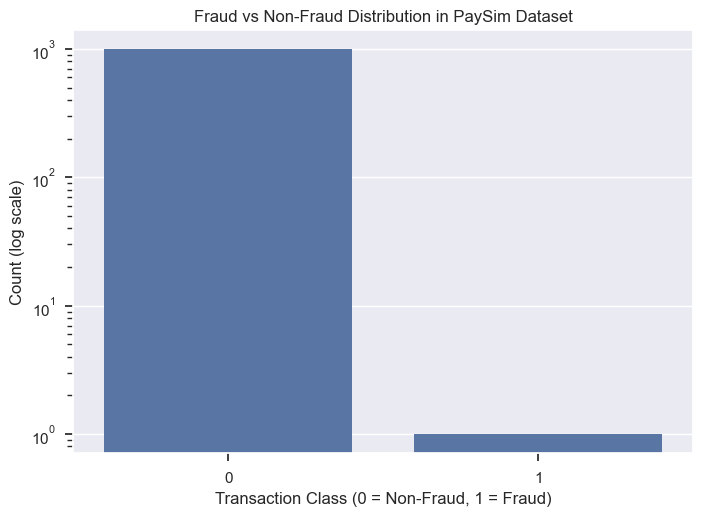

In [68]:
# plotting class distribution
sns.barplot(
    x='Class',
    y='Count', 
    data=class_count_df
)

plt.yscale('log')
plt.title('Fraud vs Non-Fraud Distribution in PaySim Dataset')
plt.xlabel("Transaction Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Count (log scale)")

plt.show()

#### Interpretation
Compared to the CreditCard dataset, PaySim shows an even rarer fraud class, making fraud detection more challenging and reinforcing the need for careful handling of imbalance.

## Missing Values & Duplicates

In [69]:
creditcard.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [70]:
paysim.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

No explicit missing values were found in any columns of sampled datasets.

In [71]:
creditcard.duplicated().sum()

np.int64(0)

In [72]:
paysim.duplicated().sum()

np.int64(0)

No duplicate rows were found in the sampled datasets.

## Feature Distribution Analysis

### CreditCard Dataset

In [ ]:
# select numerical columns
target_col = 'Class'
num_cols = creditcard.select_dtypes(include=['int64','float64']).drop(columns=[target_col])

print(f"number of numerical columns: {len(num_cols.columns)}")

number of numerical columns: 30


#### Interpretable Features: 'Amount' & 'Time'

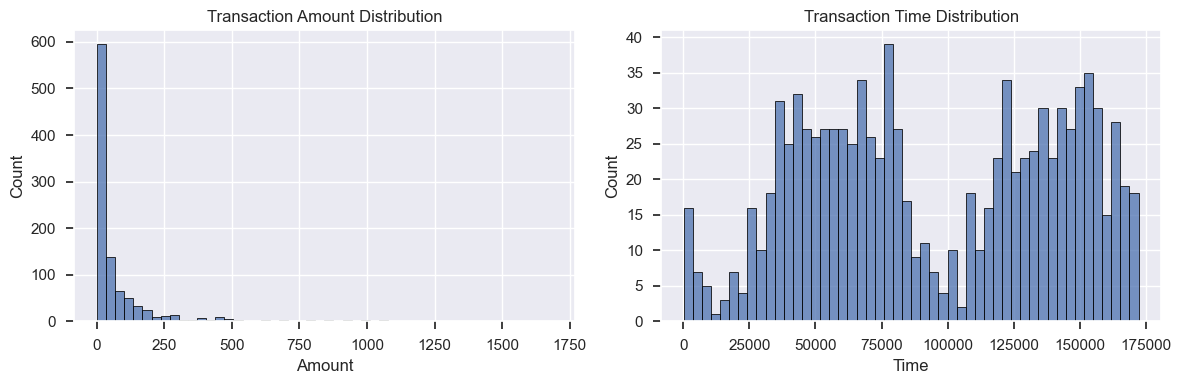

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(creditcard['Amount'], bins=50, ax=axes[0])
axes[0].set_title('Transaction Amount Distribution')

sns.histplot(creditcard['Time'], bins=50, ax=axes[1])
axes[1].set_title('Transaction Time Distribution')

plt.tight_layout()
plt.show()

The 'Amount' distribution are heavily right-skewed with most transactions involving small values and only a few extremely large ones. 

The 'Time' feature shows a multi-modal distribution with several peaks. We can observe two similar peaks in the histogram which suggest daily transaction cycles, likely reflecting consumer behavior patterns. It matches the dataset's two-day time period.

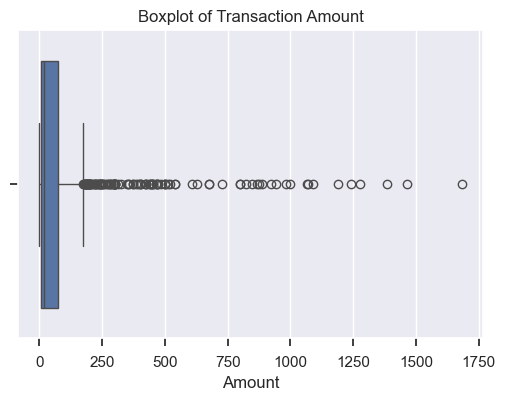

In [28]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=creditcard['Amount'])
plt.title('Boxplot of Transaction Amount')
plt.show()

We can see the same pattern of distribution here as well: It is highly right-skewed with the majority of transactions concentrated at low values. Because of this extreme skewness, the raw 'Amount' feature is unsuitable for direct modeling and requires transformation and scaling. 

#### PCA features

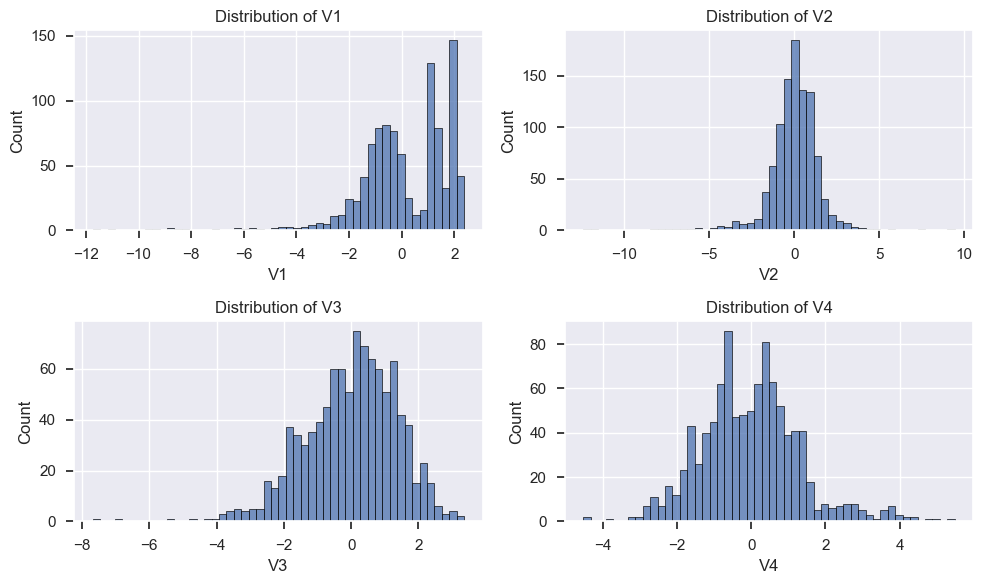

In [29]:
# a subset of PCA features (V1-V4)
pca_features = [f'V{i}' for i in range(1, 5)]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for i, col in enumerate(pca_features):
    sns.histplot(creditcard[col], bins=50, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

Several PCA components show skewness and heavy tails. While PCA ensures centering and decorrelation, it does not enforce normality. Downstream models and preprocessing steps should account for this behavior. 

## PaySim Dataset